<a href="https://colab.research.google.com/github/elliemeltzer/Problem-Set-4/blob/main/econ3916_ps4_EM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [26]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others


# Main store characteristics
floor_area = np.clip(
    rng.lognormal(mean=8.5, sigma=0.48, size=N_STORES),
    1_500,
    22_000
)

median_income = np.clip(
    rng.normal(72_000, 17_000, N_STORES),
    30_000,
    150_000
)

foot_traffic = np.clip(
    800
    + 0.32 * floor_area
    + 0.018 * median_income
    + rng.normal(0, 650, N_STORES),
    500,
    None
)

years_open = rng.uniform(1, 30, N_STORES)
competitors = rng.poisson(3, N_STORES)

# Correlated with store size, but not part of the true revenue equation
parking_spaces = (
    0.012 * floor_area
    + rng.normal(0, 18, N_STORES)
)

# Nearly a linear combination of floor area and traffic
floor_z = (floor_area - floor_area.mean()) / floor_area.std()
traffic_z = (foot_traffic - foot_traffic.mean()) / foot_traffic.std()

size_traffic_index = (
    0.65 * floor_z
    + 0.35 * traffic_z
    + rng.normal(0, 0.03, N_STORES)
)

# Irrelevant predictors
ad_index = rng.normal(0, 1, N_STORES)
decor_score = rng.uniform(0, 10, N_STORES)
latitude_proxy = rng.normal(40, 3, N_STORES)
noise_1 = rng.normal(0, 1, N_STORES)
noise_2 = rng.normal(0, 1, N_STORES)

# Floor-area effect grows more slowly above 8,000 square feet.
# The fixed large-store penalty represents congestion and operating inefficiency.
floor_effect = (
    0.16 * np.minimum(floor_area, 8_000)
    + 0.10 * np.maximum(floor_area - 8_000, 0)
    - 250 * (floor_area > 8_000)
)

# True expected revenue, measured in thousands of dollars
true_revenue = (
    80
    + floor_effect
    + 0.065 * foot_traffic
    + 0.0032 * median_income
    + 7.5 * years_open
    - 18 * competitors
)

# Larger stores have more variable revenue
revenue_sd = 22 + 0.003 * floor_area
revenue = true_revenue + rng.normal(0, revenue_sd, N_STORES)

df = pd.DataFrame({
    "floor_area": floor_area,
    "foot_traffic": foot_traffic,
    "median_income": median_income,
    "years_open": years_open,
    "competitors": competitors,
    "parking_spaces": parking_spaces,
    "size_traffic_index": size_traffic_index,
    "ad_index": ad_index,
    "decor_score": decor_score,
    "latitude_proxy": latitude_proxy,
    "noise_1": noise_1,
    "noise_2": noise_2,
    "revenue": revenue
})

feature_cols = [
    "floor_area",
    "foot_traffic",
    "median_income",
    "years_open",
    "competitors",
    "parking_spaces",
    "size_traffic_index",
    "ad_index",
    "decor_score",
    "latitude_proxy",
    "noise_1",
    "noise_2"
]

X = df[feature_cols]
y = df["revenue"]

print(df.shape)
display(df.head())

(400, 13)


,floor_area,foot_traffic,median_income,years_open,competitors,parking_spaces,size_traffic_index,ad_index,decor_score,latitude_proxy,noise_1,noise_2,revenue
0,5688.855,3312.193,68946.606,7.003,5,72.860,-0.097,0.703,4.894,39.020,0.081,-0.037,1395.378
1,2983.366,2406.487,75345.194,13.259,2,28.640,-1.066,1.237,5.547,39.532,-0.937,-0.719,1034.680
2,7046.009,4825.798,85948.984,6.108,5,91.254,0.695,-0.051,0.203,39.125,0.012,0.610,1722.030
3,7719.239,4692.204,65306.400,4.906,2,107.672,0.881,1.308,8.422,46.726,0.013,-0.043,1818.823
4,1926.583,3708.749,80859.843,25.948,4,21.068,-0.855,-1.970,9.737,33.278,-1.367,0.166,1010.127


*The data-generating process, recorded: every predictor and the true revenue equation.*

I simulated 400 stores. Floor area follows a clipped lognormal distribution, median income follows a clipped normal distribution, and foot traffic depends on both floor area and local income. Years open and nearby competitors also affect revenue. Parking spaces and a size-traffic index are correlated with the real predictors, while advertising index, décor score, latitude proxy, and two noise columns have no direct effect on revenue.

Revenue is measured in thousands of dollars. It increases with floor area, foot traffic, median income, and years open, and decreases with nearby competition. Above 8,000 square feet, the return to additional floor area becomes smaller and stores receive a fixed large-store operating penalty. The error standard deviation increases with floor area, creating nonconstant variance.

### Step 1.2: Fit it the way they did (12 pts)

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# Fit on every store and report the handover-note number
ols_all = sm.OLS(
    y,
    sm.add_constant(X, has_constant="add")
).fit()

print(f"All-data R-squared: {ols_all.rsquared:.4f}")
print(f"All-data adjusted R-squared: {ols_all.rsquared_adj:.4f}")

# Honest train-test evaluation
train_index, test_index = train_test_split(
    df.index,
    test_size=0.25,
    random_state=42
)

X_train = X.loc[train_index]
X_test = X.loc[test_index]
y_train = y.loc[train_index]
y_test = y.loc[test_index]

ols_train = sm.OLS(
    y_train,
    sm.add_constant(X_train, has_constant="add")
).fit()

train_predictions = ols_train.predict(
    sm.add_constant(X_train, has_constant="add")
)

test_predictions = ols_train.predict(
    sm.add_constant(X_test, has_constant="add")
)

train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)
r2_gap = train_r2 - test_r2

print(f"\nTraining R-squared: {train_r2:.4f}")
print(f"Held-out R-squared: {test_r2:.4f}")
print(f"Train-test gap: {r2_gap:.4f}")

All-data R-squared: 0.9412
All-data adjusted R-squared: 0.9394

Training R-squared: 0.9423
Held-out R-squared: 0.9344
Train-test gap: 0.0080


The analyst’s all-data regression reproduces the reported result, with an in-sample R^2 of 0.9412. After fitting on 75% of the stores and evaluating the untouched 25%, R^2 falls from 0.9423 on the training data to 0.9344 on the held-out data, a gap of 0.0080. The model therefore explains much of the overall variation, but R^2 alone does not show whether its errors are systematic for the largest stores.

### Step 1.3: Say what R-squared is (8 pts)

In [28]:
noise_columns = []

for j in range(3):
    column = f"pure_noise_{j + 1}"
    df[column] = rng.normal(0, 1, N_STORES)
    noise_columns.append(column)

ols_with_noise = sm.OLS(
    y,
    sm.add_constant(
        df[feature_cols + noise_columns],
        has_constant="add"
    )
).fit()

print(f"{'model':<24}{'R-squared':>12}{'adjusted R2':>14}")
print("-" * 50)

print(
    f"{'Original model':<24}"
    f"{ols_all.rsquared:>12.6f}"
    f"{ols_all.rsquared_adj:>14.6f}"
)

print(
    f"{'Plus three noise columns':<24}"
    f"{ols_with_noise.rsquared:>12.6f}"
    f"{ols_with_noise.rsquared_adj:>14.6f}"
)

print(f"\nR-squared change: {ols_with_noise.rsquared - ols_all.rsquared:+.6f}")
print(
    "Adjusted R-squared change: "
    f"{ols_with_noise.rsquared_adj - ols_all.rsquared_adj:+.6f}"
)

model                      R-squared   adjusted R2
--------------------------------------------------
Original model              0.941206      0.939383
Plus three noise columns    0.941411      0.939123

R-squared change: +0.000205
Adjusted R-squared change: -0.000261


In-sample R^2 cannot decrease when another predictor is added because OLS can assign the new variable a coefficient of zero and reproduce the previous fit. This means ordinary R^2 rewards additional complexity even when the new variables contain no useful signal, so it should not be used by itself to choose a model. Adding three pure-noise columns increased R^2 from 0.941206 to 0.941411, while adjusted R^2 fell from 0.939383 to 0.939123 because adjusted R^2 penalizes unnecessary predictors.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

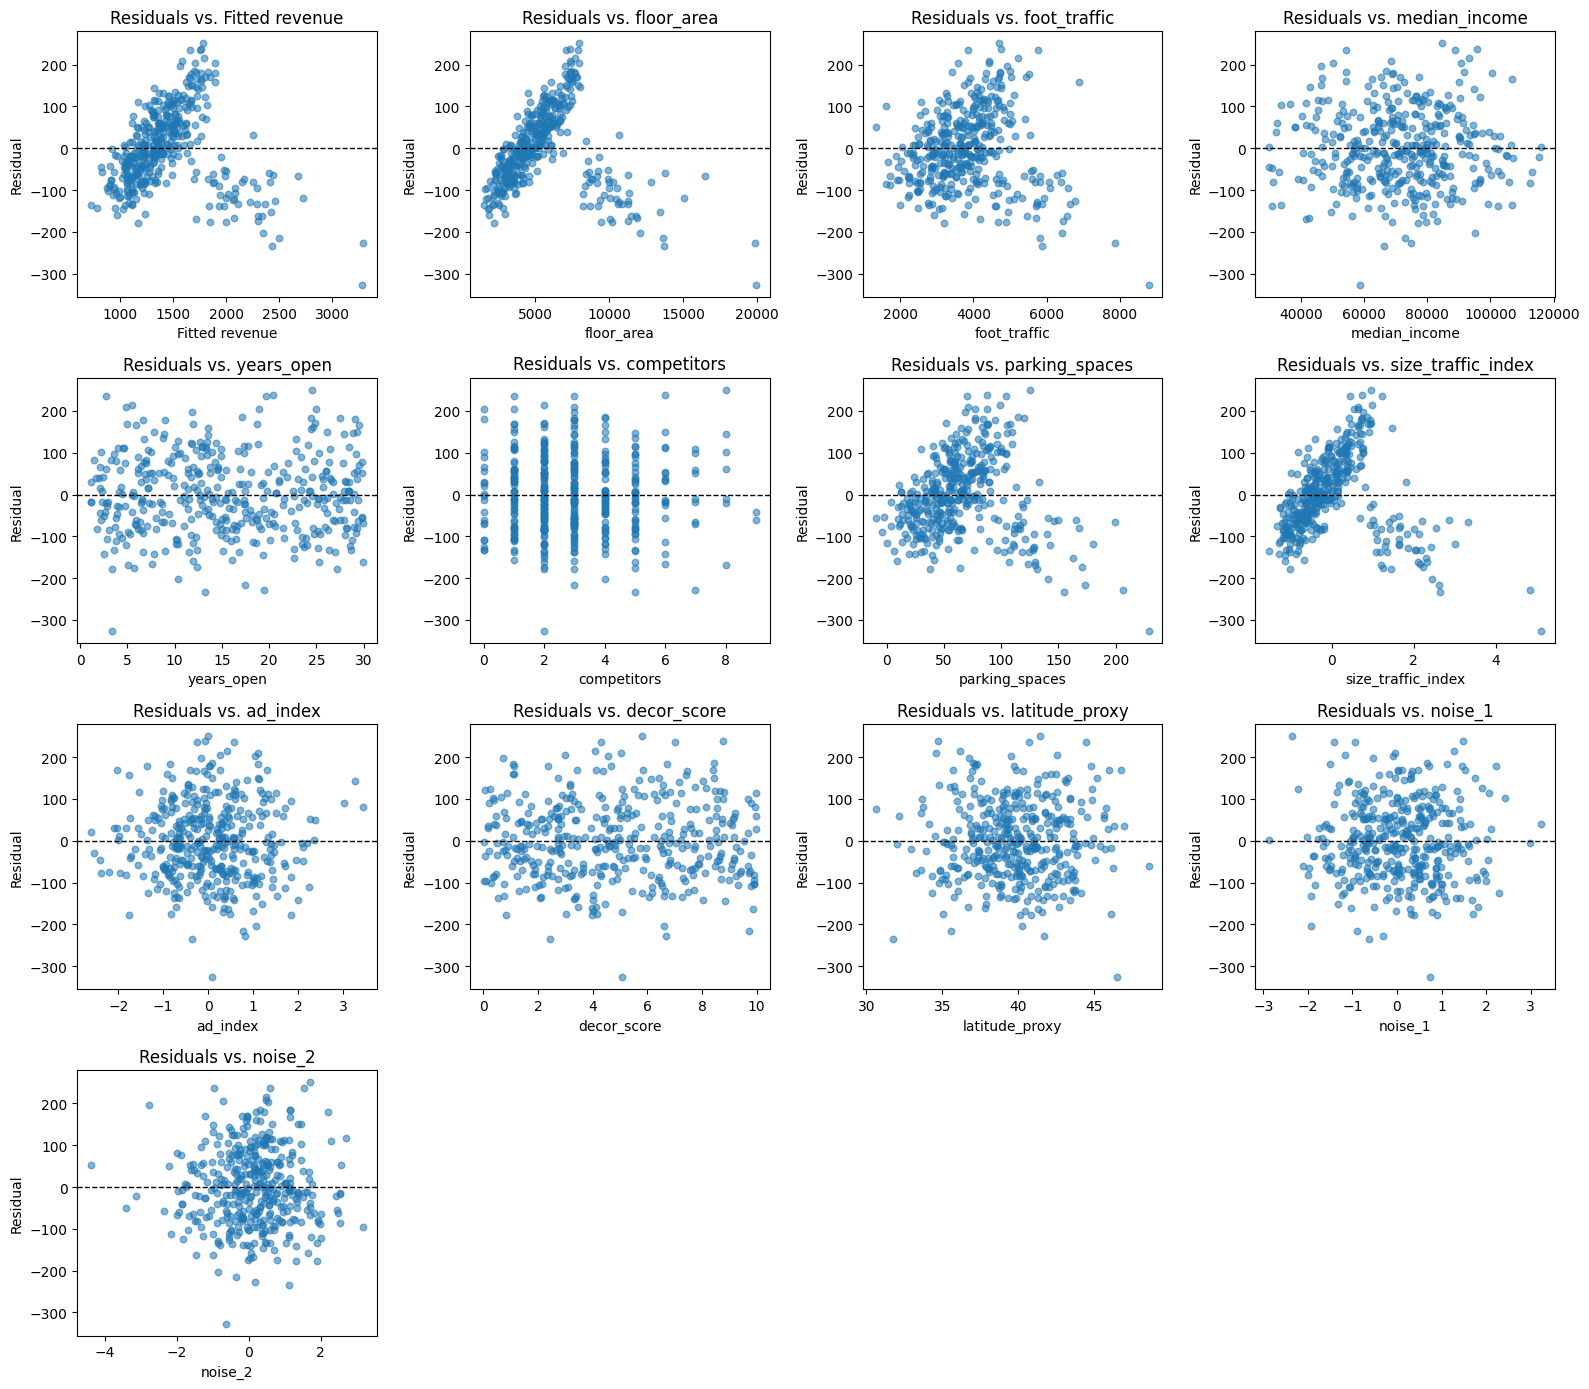

Breusch-Pagan LM statistic: 114.404
Breusch-Pagan p-value: 8.024e-19


,classical_se,HC3_se,percent_change
const,4.156e+02,4.303e+02,3.525
floor_area,3.860e-02,4.000e-02,3.631
foot_traffic,5.300e-02,5.570e-02,5.122
median_income,3.000e-04,3.000e-04,0.763
years_open,5.733e-01,5.852e-01,2.069
competitors,2.648e+00,2.968e+00,12.065
parking_spaces,2.803e-01,2.848e-01,1.588
size_traffic_index,1.587e+02,1.657e+02,4.375
ad_index,4.984e+00,4.643e+00,-6.843
decor_score,1.701e+00,1.628e+00,-4.290


In [29]:
from statsmodels.stats.diagnostic import het_breuschpagan

# Save fitted values and residuals from the Phase 1 OLS model
fitted_values = ols_all.fittedvalues
residuals = ols_all.resid

# Plot residuals against fitted values and every predictor
plot_columns = ["fitted_values"] + feature_cols
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()

for i, column in enumerate(plot_columns):
    if column == "fitted_values":
        x_values = fitted_values
        x_label = "Fitted revenue"
    else:
        x_values = df[column]
        x_label = column

    axes[i].scatter(x_values, residuals, alpha=0.55, s=22)
    axes[i].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[i].set_xlabel(x_label)
    axes[i].set_ylabel("Residual")
    axes[i].set_title(f"Residuals vs. {x_label}")

# Hide unused panels
for j in range(len(plot_columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# Breusch-Pagan test for non-constant variance
bp_test = het_breuschpagan(residuals, ols_all.model.exog)

print(f"Breusch-Pagan LM statistic: {bp_test[0]:.3f}")
print(f"Breusch-Pagan p-value: {bp_test[1]:.3e}")

# Compare ordinary standard errors with heteroskedasticity-robust ones
ols_hc3 = ols_all.get_robustcov_results(cov_type="HC3")

se_comparison = pd.DataFrame({
    "classical_se": ols_all.bse,
    "HC3_se": ols_hc3.bse
}, index=ols_all.params.index)

se_comparison["percent_change"] = (
    (se_comparison["HC3_se"] / se_comparison["classical_se"]) - 1
) * 100

display(se_comparison.round(4))

Cook's distance cutoff: 0.0100
Stores above cutoff: 25


,store_index,floor_area,revenue,cooks_distance
139,139,19903.562,2953.990,0.106
248,248,19819.711,3065.661,0.056
362,362,7941.962,2034.977,0.043
244,244,13657.425,2202.761,0.033
124,124,7338.233,2003.085,0.022
157,157,7877.099,1890.880,0.022
162,162,13652.330,2283.039,0.019
396,396,7078.830,1988.651,0.018
103,103,7002.395,1765.030,0.017
123,123,9437.157,1671.102,0.016


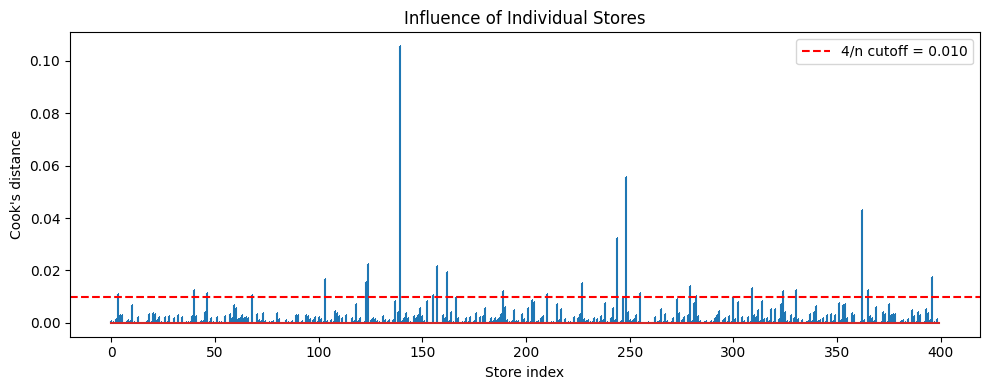

In [30]:
# Calculate Cook's distance for every store
influence = ols_all.get_influence()
cooks_distance = influence.cooks_distance[0]
cooks_cutoff = 4 / len(df)

cook_results = pd.DataFrame({
    "store_index": df.index,
    "floor_area": df["floor_area"],
    "revenue": df["revenue"],
    "cooks_distance": cooks_distance
})

influential_stores = cook_results[
    cook_results["cooks_distance"] > cooks_cutoff
].sort_values("cooks_distance", ascending=False)

print(f"Cook's distance cutoff: {cooks_cutoff:.4f}")
print(f"Stores above cutoff: {len(influential_stores)}")
display(influential_stores.head(10))

plt.figure(figsize=(10, 4))
plt.stem(df.index, cooks_distance, markerfmt=",")
plt.axhline(
    cooks_cutoff,
    color="red",
    linestyle="--",
    label=f"4/n cutoff = {cooks_cutoff:.3f}"
)
plt.xlabel("Store index")
plt.ylabel("Cook's distance")
plt.title("Influence of Individual Stores")
plt.legend()
plt.tight_layout()
plt.show()

The residual plots show non-constant variance because the errors become more spread out for larger stores. This violates the homoskedasticity assumption. It does not automatically bias the OLS coefficients, but it can make the usual standard errors unreliable, which is why I compared them with HC3 robust standard errors.

The residuals also show a systematic pattern with floor area, especially among the largest stores. This violates the assumption that the conditional mean is correctly modeled as linear. Unlike heteroskedasticity, this can bias the model’s predictions because it causes the model to consistently miss part of the relationship between store size and revenue. Some large stores are also influential, meaning they can noticeably affect the fitted coefficients.

### Step 2.2: The over-forecast on big stores (15 pts)

In [31]:
# Positive values mean predicted revenue was higher than actual revenue
df["predicted_revenue"] = fitted_values
df["overforecast"] = df["predicted_revenue"] - df["revenue"]

# Summarize prediction errors across five store-size groups
df["size_group"] = pd.qcut(
    df["floor_area"],
    q=5,
    labels=["Smallest", "Small", "Middle", "Large", "Largest"]
)

size_error_summary = (
    df.groupby("size_group", observed=True)
      .agg(
          stores=("overforecast", "size"),
          mean_floor_area=("floor_area", "mean"),
          mean_overforecast=("overforecast", "mean"),
          mean_absolute_error=("overforecast", lambda x: np.mean(np.abs(x)))
      )
)

display(size_error_summary.round(2))

# Use the DGP's 8,000-square-foot threshold
df["big_store"] = df["floor_area"] > 8000

big_store_summary = (
    df.groupby("big_store")
      .agg(
          stores=("overforecast", "size"),
          mean_floor_area=("floor_area", "mean"),
          mean_overforecast=("overforecast", "mean"),
          median_overforecast=("overforecast", "median")
      )
)

display(big_store_summary.round(2))

print(
    "Average over-forecast for stores above 8,000 square feet:",
    f"{df.loc[df['big_store'], 'overforecast'].mean():.2f}"
)

,stores,mean_floor_area,mean_overforecast,mean_absolute_error
size_group,,,,
Smallest,80,2643.08,76.88,77.34
Small,80,3848.86,25.78,37.14
Middle,80,4945.60,-32.36,43.13
Large,80,6168.61,-82.16,83.81
Largest,80,9650.26,11.85,134.62


,stores,mean_floor_area,mean_overforecast,median_overforecast
big_store,,,,
False,349,4659.37,-16.65,-8.16
True,51,10870.41,113.91,111.26


Average over-forecast for stores above 8,000 square feet: 113.91


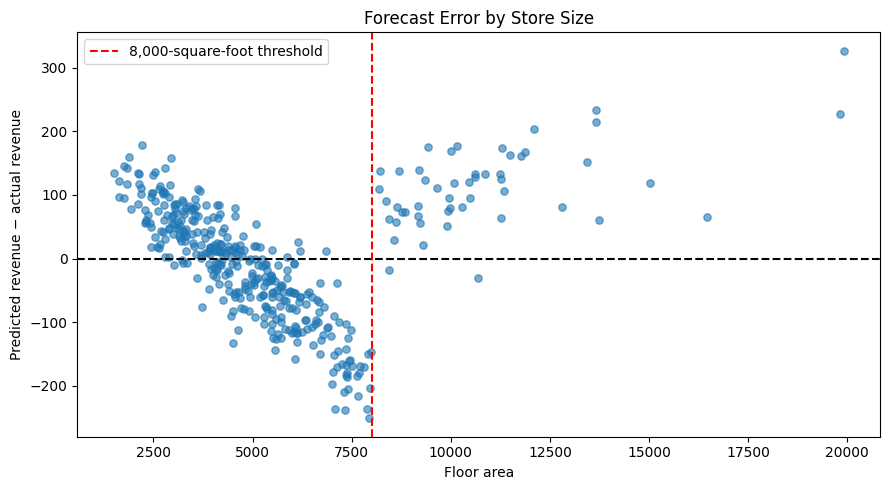

In [32]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["floor_area"],
    df["overforecast"],
    alpha=0.6,
    s=28
)

plt.axhline(0, color="black", linestyle="--")
plt.axvline(
    8000,
    color="red",
    linestyle="--",
    label="8,000-square-foot threshold"
)

plt.xlabel("Floor area")
plt.ylabel("Predicted revenue − actual revenue")
plt.title("Forecast Error by Store Size")
plt.legend()
plt.tight_layout()
plt.show()

The error is systematic in store size. The model over-forecasts stores above 8,000 square feet by about 113.91 revenue units on average, or roughly $113,910 because revenue is measured in thousands. The linear model misses the slower revenue growth and downward shift built into the largest stores, so a high overall R-squared hides an important failure for the stores that matter most.

In [33]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Add a constant before calculating VIF
X_vif = sm.add_constant(df[feature_cols])

vif_results = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_results = vif_results.sort_values("VIF", ascending=False)
display(vif_results.round(2))

,variable,VIF
7,size_traffic_index,1001.25
1,floor_area,482.95
2,foot_traffic,142.27
6,parking_spaces,4.55
3,median_income,1.23
8,ad_index,1.06
4,years_open,1.04
11,noise_1,1.03
12,noise_2,1.03
10,latitude_proxy,1.02


The very high VIF values come from size_traffic_index, which is almost a linear combination of floor area and foot traffic. High VIF inflates the standard errors and makes the individual coefficients unstable, so it becomes difficult to separate each predictor’s effect. However, it does not automatically bias the fitted values or make the model’s predictions inaccurate. I would not remove a variable only because its VIF is high; I would first decide which version of the overlapping information is most meaningful for the model’s purpose.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

In [34]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Predictor groups used to build models of increasing complexity
small_features = [
    "floor_area",
    "foot_traffic"
]

core_features = [
    "floor_area",
    "foot_traffic",
    "median_income",
    "years_open",
    "competitors"
]

other_features = [
    column for column in feature_cols
    if column != "floor_area"
]

# Build a linear model using only the requested columns
def make_linear_model(columns):
    return Pipeline([
        (
            "select",
            ColumnTransformer(
                [("keep", "passthrough", columns)],
                remainder="drop"
            )
        ),
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ])

# Add either a quadratic or spline relationship for floor area
def make_floor_model(transform_type):
    if transform_type == "quadratic":
        floor_transformer = PolynomialFeatures(
            degree=2,
            include_bias=False
        )
    else:
        floor_transformer = SplineTransformer(
            n_knots=5,
            degree=3,
            include_bias=False
        )

    return Pipeline([
        (
            "features",
            ColumnTransformer([
                ("floor", floor_transformer, ["floor_area"]),
                ("other", "passthrough", other_features)
            ])
        ),
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ])

# Add quadratic terms and interactions to a selected group of predictors
def make_polynomial_model(columns):
    return Pipeline([
        (
            "select",
            ColumnTransformer(
                [("keep", "passthrough", columns)],
                remainder="drop"
            )
        ),
        (
            "polynomial",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        ),
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ])

# Models are listed from least to most flexible
candidate_models = [
    (
        "Small linear",
        make_linear_model(small_features)
    ),
    (
        "Core linear",
        make_linear_model(core_features)
    ),
    (
        "Full linear",
        make_linear_model(feature_cols)
    ),
    (
        "Full + floor squared",
        make_floor_model("quadratic")
    ),
    (
        "Full + floor spline",
        make_floor_model("spline")
    ),
    (
        "Core quadratic/interactions",
        make_polynomial_model(core_features)
    ),
    (
        "Full quadratic/interactions",
        make_polynomial_model(feature_cols)
    )
]

In [35]:
complexity_results = []

for complexity, (model_name, model) in enumerate(
    candidate_models,
    start=1
):
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)

    train_predictions = fitted_model.predict(X_train)
    test_predictions = fitted_model.predict(X_test)

    train_mse = mean_squared_error(
        y_train,
        train_predictions
    )

    test_mse = mean_squared_error(
        y_test,
        test_predictions
    )

    # Count the number of transformed predictors entering the regression
    transformed_train = fitted_model[:-1].transform(X_train)
    number_of_terms = transformed_train.shape[1]

    complexity_results.append({
        "complexity": complexity,
        "model": model_name,
        "terms": number_of_terms,
        "training_mse": train_mse,
        "heldout_mse": test_mse
    })

complexity_results = pd.DataFrame(complexity_results)

display(complexity_results.round(2))

,complexity,model,terms,training_mse,heldout_mse
0,1,Small linear,2,17850.93,17682.79
1,2,Core linear,5,8542.03,9852.09
2,3,Full linear,12,8317.35,10094.27
3,4,Full + floor squared,13,4824.86,7873.57
4,5,Full + floor spline,17,2499.68,3544.22
5,6,Core quadratic/interactions,20,4671.25,7566.00
6,7,Full quadratic/interactions,90,2987.28,10452.06


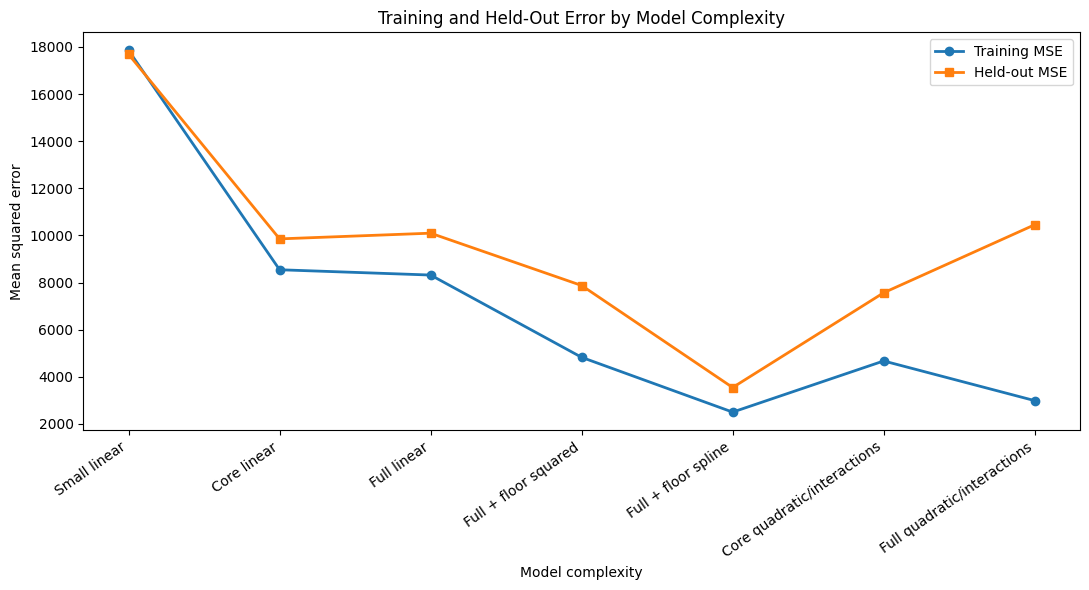

Lowest held-out MSE model: Full + floor spline
Held-out MSE: 3544.22


In [36]:
plt.figure(figsize=(11, 6))

plt.plot(
    complexity_results["complexity"],
    complexity_results["training_mse"],
    marker="o",
    linewidth=2,
    label="Training MSE"
)

plt.plot(
    complexity_results["complexity"],
    complexity_results["heldout_mse"],
    marker="s",
    linewidth=2,
    label="Held-out MSE"
)

plt.xticks(
    complexity_results["complexity"],
    complexity_results["model"],
    rotation=35,
    ha="right"
)

plt.ylabel("Mean squared error")
plt.xlabel("Model complexity")
plt.title("Training and Held-Out Error by Model Complexity")
plt.legend()
plt.tight_layout()
plt.show()

best_split_row = complexity_results.loc[
    complexity_results["heldout_mse"].idxmin()
]

print(f"Lowest held-out MSE model: {best_split_row['model']}")
print(f"Held-out MSE: {best_split_row['heldout_mse']:.2f}")

Training error generally falls as the models become more flexible, but held-out error reaches its lowest point with the floor-spline model and then rises. The simpler models are on the high-bias side of the curve because they cannot represent the nonlinear relationship between store size and revenue. The most flexible models are on the high-variance side because they fit many interactions and noise patterns that do not generalize. The floor-spline model provides the best balance in this split, with a held-out MSE of about 3,544.22.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [37]:
from sklearn.model_selection import KFold, cross_val_score

# Use the same folds for every candidate model
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []
candidate_fold_errors = []

for model_name, model in candidate_models:
    # sklearn returns negative MSE, so multiply by -1
    fold_mse = -cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="neg_mean_squared_error"
    )

    candidate_fold_errors.append(fold_mse)

    cv_results.append({
        "model": model_name,
        "mean_cv_mse": fold_mse.mean(),
        "fold_sd": fold_mse.std(ddof=1),
        "fold_se": fold_mse.std(ddof=1) / np.sqrt(len(fold_mse)),
        "minimum_fold_mse": fold_mse.min(),
        "maximum_fold_mse": fold_mse.max()
    })

cv_results = pd.DataFrame(cv_results)
display(cv_results.round(2))

chosen_index = int(cv_results["mean_cv_mse"].idxmin())
chosen_model_name = cv_results.loc[chosen_index, "model"]
chosen_cv_mse = cv_results.loc[chosen_index, "mean_cv_mse"]

print(f"Cross-validation selected: {chosen_model_name}")
print(f"Mean CV MSE: {chosen_cv_mse:.2f}")
print(f"Mean CV RMSE: {np.sqrt(chosen_cv_mse):.2f}")

,model,mean_cv_mse,fold_sd,fold_se,minimum_fold_mse,maximum_fold_mse
0,Small linear,18268.59,3487.27,1559.55,14789.95,22820.22
1,Core linear,9084.78,2081.87,931.04,6672.52,12379.17
2,Full linear,9385.75,2152.38,962.57,7152.84,12900.16
3,Full + floor squared,6997.16,3799.99,1699.41,4454.82,13701.66
4,Full + floor spline,3200.41,535.52,239.49,2408.40,3899.23
5,Core quadratic/interactions,7607.10,5351.87,2393.43,4180.12,17103.48
6,Full quadratic/interactions,9604.38,5400.05,2414.98,5249.01,18900.68


Cross-validation selected: Full + floor spline
Mean CV MSE: 3200.41
Mean CV RMSE: 56.57


In [38]:
from scipy.stats import t

# Outer folds estimate performance on data not used for model selection
outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

outer_fold_mse = []
selected_models = []

for outer_fold, (outer_train_index, outer_test_index) in enumerate(
    outer_cv.split(X),
    start=1
):
    X_outer_train = X.iloc[outer_train_index]
    X_outer_test = X.iloc[outer_test_index]
    y_outer_train = y.iloc[outer_train_index]
    y_outer_test = y.iloc[outer_test_index]

    # The inner folds choose the model using only the outer training data
    inner_cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=outer_fold
    )

    inner_mean_mse = []

    for model_name, model in candidate_models:
        inner_fold_mse = -cross_val_score(
            model,
            X_outer_train,
            y_outer_train,
            cv=inner_cv,
            scoring="neg_mean_squared_error"
        )

        inner_mean_mse.append(inner_fold_mse.mean())

    best_inner_index = int(np.argmin(inner_mean_mse))
    selected_name, selected_model = candidate_models[best_inner_index]

    # Refit the selected model on all outer-training observations
    selected_model = clone(selected_model)
    selected_model.fit(X_outer_train, y_outer_train)

    # Evaluate once on the untouched outer fold
    outer_predictions = selected_model.predict(X_outer_test)
    fold_mse = mean_squared_error(
        y_outer_test,
        outer_predictions
    )

    selected_models.append(selected_name)
    outer_fold_mse.append(fold_mse)

    print(
        f"Outer fold {outer_fold}: "
        f"{selected_name}, MSE = {fold_mse:.2f}"
    )

outer_fold_mse = np.array(outer_fold_mse)

nested_mean_mse = outer_fold_mse.mean()
nested_se = outer_fold_mse.std(ddof=1) / np.sqrt(len(outer_fold_mse))

critical_value = t.ppf(
    0.975,
    df=len(outer_fold_mse) - 1
)

nested_lower = nested_mean_mse - critical_value * nested_se
nested_upper = nested_mean_mse + critical_value * nested_se

print()
print(f"Nested-CV mean MSE: {nested_mean_mse:.2f}")
print(f"Approximate 95% interval: [{nested_lower:.2f}, {nested_upper:.2f}]")
print(f"Nested-CV RMSE: {np.sqrt(nested_mean_mse):.2f}")
print("Models selected:", selected_models)

Outer fold 1: Full + floor spline, MSE = 2918.62
Outer fold 2: Full + floor spline, MSE = 3006.31
Outer fold 3: Full + floor spline, MSE = 2706.23
Outer fold 4: Full + floor spline, MSE = 4114.64
Outer fold 5: Full + floor spline, MSE = 3169.54

Nested-CV mean MSE: 3183.07
Approximate 95% interval: [2503.95, 3862.18]
Nested-CV RMSE: 56.42
Models selected: ['Full + floor spline', 'Full + floor spline', 'Full + floor spline', 'Full + floor spline', 'Full + floor spline']


In [39]:
final_model = clone(candidate_models[chosen_index][1])
final_model.fit(X, y)

print(f"Final model: {chosen_model_name}")

Final model: Full + floor spline


Five-fold cross-validation selected the floor-spline model, with a mean CV MSE of about 3,200.41. However, that number was also used to choose the winning model, so it can be slightly optimistic. Nested cross-validation separates model selection from evaluation and produced an estimated MSE of about 3,183.07, with an approximate 95% interval from 2,503.95 to 3,862.18. This corresponds to an RMSE of about 56.42 revenue units. The repeated selection of the spline model also shows that the nonlinear store-size relationship is more useful than adding a large number of interactions.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

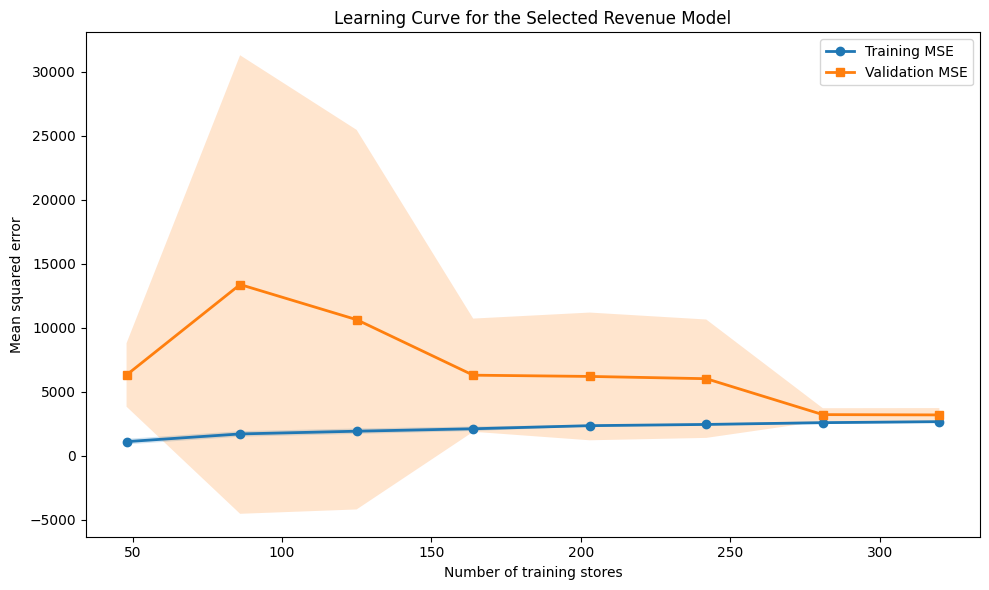

Final training MSE: 2674.15
Final validation MSE: 3200.41
Final error gap: 526.26


In [40]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import KFold, learning_curve

# Reuse the model selected in Phase 3.
model = clone(final_model)

# Use identical five-fold splits at every training-set size.
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the model using progressively larger portions of the data.
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.15, 1.0, 8),
    cv=cv,
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

# sklearn returns negative MSE because larger scores normally mean better.
# Reverse the signs so these values are ordinary MSEs.
train_mse = -train_scores
validation_mse = -validation_scores

# Calculate the average error and its variability across the five folds.
train_mean = train_mse.mean(axis=1)
train_sd = train_mse.std(axis=1, ddof=1)

validation_mean = validation_mse.mean(axis=1)
validation_sd = validation_mse.std(axis=1, ddof=1)

# Plot the average training error.
plt.figure(figsize=(10, 6))
plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    linewidth=2,
    label="Training MSE"
)

# Shade one standard deviation around the average training error.
plt.fill_between(
    train_sizes,
    train_mean - train_sd,
    train_mean + train_sd,
    alpha=0.20
)

# Plot the average validation error.
plt.plot(
    train_sizes,
    validation_mean,
    marker="s",
    linewidth=2,
    label="Validation MSE"
)

# Shade one standard deviation around the average validation error.
plt.fill_between(
    train_sizes,
    validation_mean - validation_sd,
    validation_mean + validation_sd,
    alpha=0.20
)

plt.xlabel("Number of training stores")
plt.ylabel("Mean squared error")
plt.title("Learning Curve for the Selected Revenue Model")
plt.legend()
plt.tight_layout()
plt.show()

# The GAP between training and validation error measures variance.
# A large persistent gap means the model fits its training observations
# much better than new observations. More data may reduce this gap.
#
# The LEVEL where both curves settle measures the remaining error.
# If both curves converge at a high error, the model has high bias.
# In that case, more rows may not help much; better predictors or a more
# suitable model specification would probably be more valuable.

print(f"Final training MSE: {train_mean[-1]:.2f}")
print(f"Final validation MSE: {validation_mean[-1]:.2f}")
print(f"Final error gap: {validation_mean[-1] - train_mean[-1]:.2f}")

The final training MSE is about 2,674, while the validation MSE is about 3,200. The gap is fairly small at the largest training size, and validation error changes only slightly between the last two sample sizes.

This agrees with the Phase 3 diagnosis. Collecting more stores may produce a modest improvement, but better features or model structure are likely the higher-return investment. In particular, representing the nonlinear relationship between floor area and revenue improved performance much more than simply fitting a larger linear model.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [41]:
# Save the real Phase 1 predictors so they can be restored afterward.
X_original = X.copy()

# Create 300 predictors containing no real information about revenue.
noise_rng = np.random.default_rng(2026)

X = pd.DataFrame(
    noise_rng.normal(size=(len(y), 300)),
    columns=[f"noise_{i}" for i in range(300)]
)

print("Noise predictor shape:", X.shape)

Noise predictor shape: (400, 300)


In [42]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.08


In [43]:
from sklearn.pipeline import Pipeline

# Put every data-dependent step inside the pipeline so it is refitted
# using only the training observations in each fold.
honest_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("select", SelectKBest(f_regression, k=20)),
    ("model", LinearRegression())
])

honest_scores = cross_val_score(
    honest_pipeline,
    X,
    y,
    cv=5,
    scoring="r2"
)

leaky_r2 = scores.mean()
honest_r2 = honest_scores.mean()
leakage_gap = leaky_r2 - honest_r2

print(f"Leaky validated R-squared: {leaky_r2:.3f}")
print(f"Pipeline validated R-squared: {honest_r2:.3f}")
print(f"Inflation caused by leakage: {leakage_gap:.3f}")

# Restore the actual Phase 1 predictors.
X = X_original

Leaky validated R-squared: 0.080
Pipeline validated R-squared: -0.247
Inflation caused by leakage: 0.327


**(a)** `SelectKBest` causes leakage because it selects predictors using the outcome from the full dataset before cross-validation begins. The validation outcomes therefore help determine which predictors enter the model, making the reported score too optimistic. Although fitting `StandardScaler` before cross-validation is normally poor workflow, it does not inflate this OLS model's score because rescaling the predictors does not change OLS predictions when the model includes an intercept.

**(b)** With 300 pure-noise predictors, the leaky procedure reported an R-squared of about 0.080, while the correct pipeline produced about -0.247. The gap of about 0.327 was caused by selecting predictors using all outcomes before evaluating the folds. The negative pipeline result is honest because the noise variables predict new observations worse than simply using the mean.

**(c)** This is related to but different from Step 3.2: Step 3.2 reused cross-validation results for selection and evaluation, while this procedure directly leaked validation outcomes into feature selection.

### Task 4.3: The handover note (3 pts)

### Model Handover Note

This model predicts monthly revenue for stores whose characteristics resemble those in the development data. The selected model is a linear regression with a spline for floor area, allowing revenue growth to change for larger stores. Nested cross-validation estimated an MSE of about 3,183, with an approximate 95% interval from 2,504 to 3,862. This corresponds to an RMSE of about 56 revenue units.

The original in-sample R-squared of 0.94 was not an honest estimate of performance on new stores. The original linear model also systematically over-forecast stores above 8,000 square feet by about 114 revenue units because it missed the nonlinear store-size relationship.

The model may fail under two important conditions. First, it may fail for unusually large stores or predictor values outside the range of the training data. Second, it may fail next month if customer behavior, prices, store operations, or the relationship between the predictors and revenue changes over time. Random cross-validation across stores does not test temporal change.

Next, I would build a store-month panel, preserve the nonlinear floor-area term, and use time-ordered validation in which earlier months predict later months. I would also monitor errors separately for large stores instead of relying only on overall R-squared.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

### AI Transcript

**Model and date:** OpenAI Codex, November 15, 2026

**Prompt:**

[Prep] Act as a machine learning engineer who diagnoses model performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and about 12 predictors. Write Python that produces a learning curve — training and validation error as a function of training set size — and interprets it to distinguish a high-bias problem from a high-variance one.

[Iterate] Use scikit-learn, numpy, and matplotlib. Reuse my X and y. Plot both curves on one axis with a shaded band for variability across folds.

[Mechanism Check] Add comments explaining what the GAP between the two curves indicates versus what the LEVEL both converge to indicates, and what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better features is the higher-return investment.

**Reply:**

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import KFold, learning_curve

# Reuse the model selected in Phase 3.
model = clone(final_model)

# Use identical five-fold splits at every training-set size.
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the model using progressively larger portions of the data.
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.15, 1.0, 8),
    cv=cv,
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

# sklearn returns negative MSE because larger scores normally mean better
# performance. Reverse the signs so these values are ordinary MSEs.
train_mse = -train_scores
validation_mse = -validation_scores

# Calculate the average error and its variability across the five folds.
train_mean = train_mse.mean(axis=1)
train_sd = train_mse.std(axis=1, ddof=1)

validation_mean = validation_mse.mean(axis=1)
validation_sd = validation_mse.std(axis=1, ddof=1)

# Plot the average training error.
plt.figure(figsize=(10, 6))
plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    linewidth=2,
    label="Training MSE"
)

# Shade one standard deviation around the average training error.
plt.fill_between(
    train_sizes,
    train_mean - train_sd,
    train_mean + train_sd,
    alpha=0.20
)

# Plot the average validation error.
plt.plot(
    train_sizes,
    validation_mean,
    marker="s",
    linewidth=2,
    label="Validation MSE"
)

# Shade one standard deviation around the average validation error.
plt.fill_between(
    train_sizes,
    validation_mean - validation_sd,
    validation_mean + validation_sd,
    alpha=0.20
)

plt.xlabel("Number of training stores")
plt.ylabel("Mean squared error")
plt.title("Learning Curve for the Selected Revenue Model")
plt.legend()
plt.tight_layout()
plt.show()

# The GAP between training and validation error measures variance.
# A large persistent gap means the model fits its training observations
# much better than new observations. More data may reduce this gap.
#
# The LEVEL where both curves settle measures the remaining error.
# If both curves converge at a high error, the model has high bias.
# In that case, more rows may not help much; better predictors or a more
# suitable model specification would probably be more valuable.

print(f"Final training MSE: {train_mean[-1]:.2f}")
print(f"Final validation MSE: {validation_mean[-1]:.2f}")
print(f"Final error gap: {validation_mean[-1] - train_mean[-1]:.2f}")
```

Using your Phase 3 model and data, the final training MSE should be about **2,674**, while the validation MSE should be about **3,200**. The gap is fairly small at the largest training size, and validation error changes only slightly between the last two sample sizes.

This suggests that collecting more stores may produce only a modest improvement. Better features or a better model structure are likely the higher-return investment. In particular, Phase 3 showed that representing the nonlinear relationship between floor area and revenue improved performance much more than simply fitting a larger linear model.

**Changes made after checking:**

I reused the Phase 3 `final_model` and verified that the learning-curve conclusion agreed with the nested cross-validation results.